# Week 10 — Where a variable comes from

**DATS 2102 · Data Visualization for Data Science**

Every chart in this course so far has started from a column someone handed you.
This short case asks a question we have not asked yet:

> **Who decided this column should exist, and what did they assume when they built it?**

We will use the Boston Housing dataset — a dataset you will meet in almost every
regression tutorial online. We are **not** using it for our modeling work this
week; we are using it once, deliberately, to see what can be hidden inside a
column name.

## 1. The dataset

Harrison and Rubinfeld published it in 1978, in a paper about how air quality
affects house prices. It became the standard teaching dataset for regression for
forty years.

It was **removed from scikit-learn in version 1.2**. `load_boston()` no longer
exists. We load it from its R archive copy instead — the point of this exercise
is to look at the thing itself.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

boston = sm.datasets.get_rdataset("Boston", "MASS").data
print(boston.shape)
print(list(boston.columns))
boston.head()

(506, 14)
['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'black', 'lstat', 'medv']


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


Thirteen predictors and `medv`, the median home value. Most of the names are
what you would expect: `rm` is rooms per dwelling, `age` is the age of the
housing stock, `nox` is nitric oxide concentration.

Two names are worth stopping on.

- `lstat` — documented as "lower status of the population"
- `black` — documented as a function of the proportion of Black residents per town

We are going to look closely at the second one.

## 2. What is actually in the column

The original paper does not store the proportion of Black residents. It stores
this instead, where `Bk` is that proportion:

$$B = 1000\,(Bk - 0.63)^2$$

A squared term. That is not a neutral choice, and before we discuss it, let us
confirm that is really the formula — we should not take a claim on trust any
more than we would take a chart on trust.

If the formula is right, the **largest possible value** happens at `Bk = 0`,
and equals $1000 \times 0.63^2$.

In [2]:
predicted_max = 1000 * 0.63 ** 2
actual_max = boston["black"].max()

print(f"formula predicts a maximum of {predicted_max:.2f}")
print(f"the column's actual maximum is {actual_max:.2f}")
print(f"match: {np.isclose(predicted_max, actual_max)}")

formula predicts a maximum of 396.90
the column's actual maximum is 396.90
match: True


The formula is confirmed. Now we can read what it says.

A squared term centered on 0.63 asserts that home values rise as a town's Black
population share moves **away from 63% in either direction**. That claim is not
a measurement. Nobody observed it. It is a hypothesis about segregation that the
authors built into the data itself — and then every person who later fit a model
on this column inherited that hypothesis without being asked whether they agreed
with it.

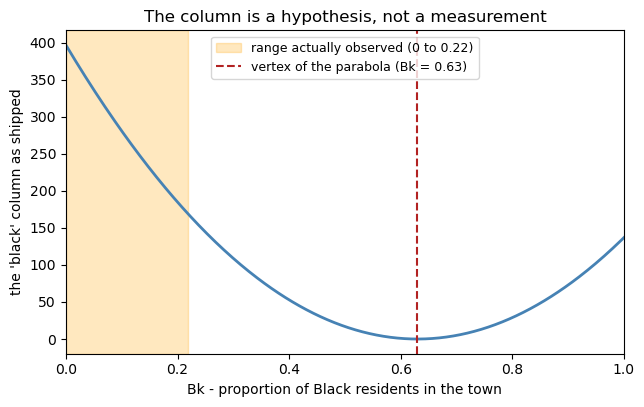

In [3]:
CENTER = 0.63

def recover_bk(b):
    """Undo the square. Returns the only root that can be a proportion."""
    root = np.sqrt(np.clip(b / 1000.0, 0, None))
    low, high = CENTER - root, CENTER + root
    return np.where(high > 1.0, low, np.nan)

bk = recover_bk(boston["black"].to_numpy())

grid = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(grid, 1000 * (grid - CENTER) ** 2, color="steelblue", lw=2)
ax.axvspan(0, np.nanmax(bk), color="orange", alpha=0.25,
           label=f"range actually observed (0 to {np.nanmax(bk):.2f})")
ax.axvline(CENTER, color="firebrick", ls="--", lw=1.5,
           label=f"vertex of the parabola (Bk = {CENTER})")
ax.set_xlabel("Bk - proportion of Black residents in the town")
ax.set_ylabel("the 'black' column as shipped")
ax.set_title("The column is a hypothesis, not a measurement")
ax.legend(loc="upper center", fontsize=9)
ax.set_xlim(0, 1)
plt.show()

Look at where the data actually lives — the shaded band.

No town in this dataset has a Black population share above 0.22. **The vertex of
the parabola, at 0.63, is never observed.** The U-shape the formula describes
cannot be tested with this data at all. Within the range that exists, the curve
is simply decreasing: a higher value of `black` means *fewer* Black residents.

## 3. The shape of the column

Now plot the column the way you would plot any unfamiliar variable — which is
what Week 3 told you to do before you model anything.

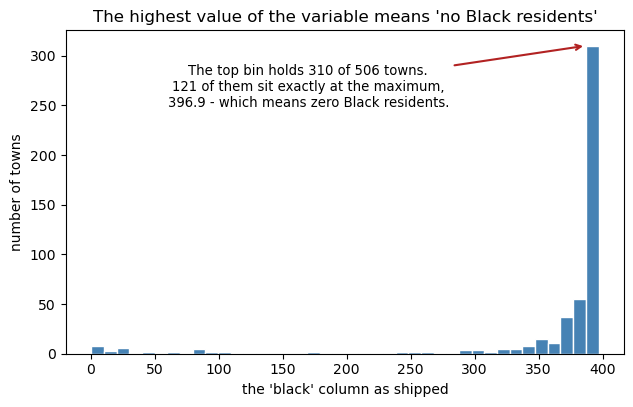

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 4.2))
counts, edges, _ = ax.hist(boston["black"], bins=40, color="steelblue", edgecolor="white")
at_max = int(np.isclose(boston["black"], 1000 * CENTER ** 2).sum())

ax.annotate(
    f"The top bin holds {int(counts[-1])} of {len(boston)} towns.\n"
    f"{at_max} of them sit exactly at the maximum,\n"
    f"396.9 - which means zero Black residents.",
    xy=(edges[-2], counts[-1]), xytext=(170, counts[-1] * 0.80),
    ha="center", fontsize=9.5,
    arrowprops=dict(arrowstyle="->", color="firebrick", lw=1.5))
ax.set_xlabel("the 'black' column as shipped")
ax.set_ylabel("number of towns")
ax.set_title("The highest value of the variable means 'no Black residents'")
plt.show()

A quarter of the towns sit at the single highest value the variable can take,
and that value encodes the absence of Black residents.

If you scanned a correlation table without knowing any of this, you would read
`black` as an ordinary quantity where bigger means more. It does not.

## 4. The part that should worry you

Here is the consequence. Fit the relationship as the data ships, then undo the
transform and fit it again.

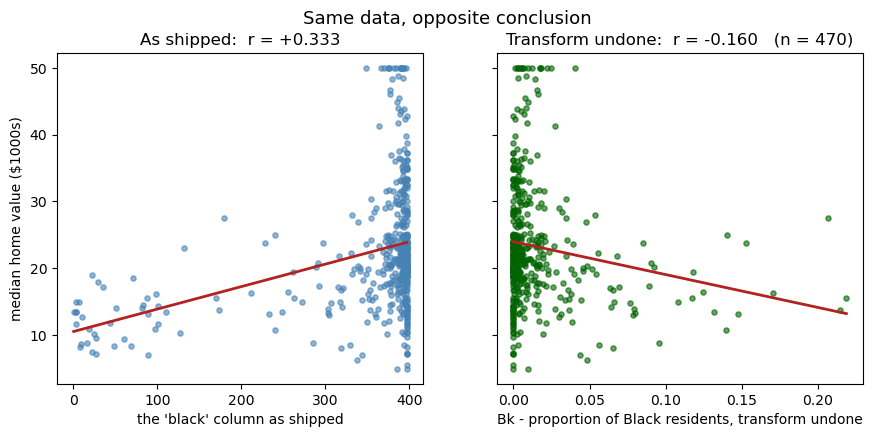

In [5]:
medv = boston["medv"].to_numpy()
B = boston["black"].to_numpy()
ok = ~np.isnan(bk)

fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.3), sharey=True)

r_shipped = np.corrcoef(B, medv)[0, 1]
axes[0].scatter(B, medv, s=14, color="steelblue", alpha=0.6)
m, c = np.polyfit(B, medv, 1)
axes[0].plot([B.min(), B.max()], m * np.array([B.min(), B.max()]) + c, color="firebrick", lw=2)
axes[0].set_xlabel("the 'black' column as shipped")
axes[0].set_ylabel("median home value ($1000s)")
axes[0].set_title(f"As shipped:  r = {r_shipped:+.3f}")

r_undone = np.corrcoef(bk[ok], medv[ok])[0, 1]
axes[1].scatter(bk[ok], medv[ok], s=14, color="darkgreen", alpha=0.6)
m2, c2 = np.polyfit(bk[ok], medv[ok], 1)
axes[1].plot([bk[ok].min(), bk[ok].max()],
             m2 * np.array([bk[ok].min(), bk[ok].max()]) + c2, color="firebrick", lw=2)
axes[1].set_xlabel("Bk - proportion of Black residents, transform undone")
axes[1].set_title(f"Transform undone:  r = {r_undone:+.3f}   (n = {ok.sum()})")

fig.suptitle("Same data, opposite conclusion", fontsize=13)
plt.show()

**The sign flips.** As shipped, the variable correlates *positively* with home
value. Undo the transform and the correlation is *negative*.

Two cautions, so you take the right lesson:

- The right-hand correlation is **weak** (about -0.16) and this is observational
  data from 1970. Neither panel establishes a cause. The point is not that we
  found the true answer; the point is that **a choice made by someone else,
  before you ever opened the file, reversed the direction of the finding.**
- The transform is not always reversible. For 36 of the 506 towns, two different
  population shares produce the same stored value and you cannot tell which is
  which. Those towns are dropped from the right-hand panel.

## 5. What to take from this

In Week 2 you learned that choosing an encoding — position, color, size — is a
design decision that carries assumptions. This case shows the same thing
happening **one step earlier**, when someone decides what to measure and how to
store it.

A chart can only be as honest as its columns. So the habits:

1. **Read the data dictionary before you plot.** A column name is a claim, and
   `black` is a claim that took us three figures to unpack.
2. **Plot the variable itself**, not just its relationship to your outcome. The
   histogram in section 3 would have raised the question on its own.
3. **Ask who built the column and why.** Derived variables carry their author's
   hypothesis forward silently.
4. **Say what you excluded, and why.** If you drop a variable on ethical
   grounds, that belongs in your write-up — it is a finding, not housekeeping.

For our actual modeling work this week we use the **Ames** and **California
housing** datasets. They are better documented, more recent, and they do not ask
you to carry someone else's assumption about race into your regression.

## Discussion

**1.** The authors could have stored `Bk` directly and let each analyst decide
how to transform it. What did they gain by storing the square instead, and who
bore the cost of that decision?

**2.** This dataset was used to teach regression for roughly forty years before
it was pulled. What would have to be true about how we teach for the problem to
have been caught sooner?

**3.** You are given a dataset for your final project with a column named
`risk_score` and no documentation. What do you do before you plot it?